# WorldView request: SERC (MD) and Gus Pearson (AZ)

NASA CMR (CSDA legacy Maxar archive) only, via `multistac`.

| Site | Target | Acceptable |
|---|---|---|
| SERC, MD | WV-2/3 leaf-on, closest to 30 Jul – 4 Aug 2017 (lidar, NEON, Sentinel-2) | Jun – Aug 2017 |
| Gus Pearson, AZ | WV-2/3 closest to May – Jun 2013 (G-LiHT flight 31 Mar 2013) | |

Both: MSI + PAN, not pan-sharpened, Level-1B (or Standard / L2A), full metadata (.IMD: calibration factors,
acquisition time, sun/view angles), cloud-free over the box, off-nadir ≤ 15° ideally (≤ 20° OK).
WV-3 SWIR wanted if available.

Steps: 1) availability timeline · 2) top 5 scenes per site · 3) download · 4) NIR-red-green quicklooks.

In [1]:
import sys, io, re, tarfile, zipfile
from pathlib import Path
sys.path.insert(0, '/home/pmontesa/code/csda_summaries/lib')

import numpy as np
import pandas as pd
import geopandas as gpd
import fiona
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin

import multistac
import multistac_plots as mp
import multistac_download as md

pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)

/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3

## Parameters

In [2]:
AOI_ZIP = '/home/pmontesa/code/csda_summaries/sites/WV_request_AOIs.zip'
OUT_DIR = Path('/home/pmontesa/pmontesa/earthdata')
CACHE_DIR = OUT_DIR / 'multistac_cache'

SEARCH_START, SEARCH_END = '2009-01-01', '2024-12-31'   # WV-2 launch .. end of the CMR archive
COLLECTIONS = ['WV02_MSI_L1B', 'WV02_Pan_L1B', 'WV03_MSI_L1B', 'WV03_Pan_L1B',
               'WV02_MSI_L2A', 'WV02_Pan_L2A', 'WV03_MSI_L2A', 'WV03_Pan_L2A']

# Per site: target window (ranking = days outside it) and allowed months (None = any)
TARGETS = {
    'SERC':       {'window': ('2017-07-30', '2017-08-04'), 'months': [5, 6, 7, 8, 9, 10]},  # leaf-on
    'GUSPEARSON': {'window': ('2013-05-01', '2013-06-30'), 'months': None},
}
OFF_NADIR_MAX = 20      # deg; <= 15 preferred (sorts first among equal dates)
CLOUD_MAX = 20          # %, CMR cloud cover of the granule(s) over the box (whole tile, not just the box)
MIN_AOI_COVER = 0.95    # fraction of the request box covered by the scene's parts
TOP_N = 5
ASSETS = ['ntf', 'tar']   # image + metadata sidecars (the .tar has no imagery)
DOWNLOAD_VIA = 'https'     # 's3' on a cloud platform (AWS us-west-2); 'https' to test from this server

## AOIs
Each site has a *request* box (DART scene + 300 m) and the exact *scene* polygon; searches use the request box.

In [3]:
def read_nested_shp(zip_path, member):
    with fiona.io.ZipMemoryFile(zipfile.ZipFile(zip_path).read(member)) as mem:
        with mem.open() as src:
            return gpd.GeoDataFrame.from_features(list(src), crs='EPSG:4326')

aois = pd.concat([read_nested_shp(AOI_ZIP, m) for m in ['SERC_MD_AOI_shp.zip', 'GusPearson_AZ_AOI_shp.zip']],
                 ignore_index=True)
sites = aois[aois.kind == 'request'].rename(columns={'site': 'site_name'})[['site_name', 'geometry']].reset_index(drop=True)
sites

,site_name,geometry
0,SERC,"POLYGON ((-76.54624 38.85944, -76.56568 38.85944, -76.56568 38.90563, -76.54624 38.905..."
1,GUSPEARSON,"POLYGON ((-111.73769 35.26326, -111.75550 35.26326, -111.75550 35.28681, -111.73769 35..."


## Search NASA CMR

In [4]:
res = multistac.search(sites, SEARCH_START, SEARCH_END, {'csda-cmr': COLLECTIONS}, cache_dir=CACHE_DIR)
print(res)

# WV-3 SWIR: is anything in CMR at these sites?
swir = multistac.search(sites, SEARCH_START, SEARCH_END, {'csda-cmr': ['WV03_SWIR_L1B']}, progress=False)
print('WV03_SWIR_L1B granules at these sites:', len(swir.gdf))

searches: 100%|██████████| 16/16 [00:00<00:00, 131328.50it/s]


SearchResult(668 rows, 668 unique items, 0 failed tasks)
WV03_SWIR_L1B granules at these sites: 0


## Scenes

CMR holds one granule per strip *part* (P001, P002, ...) and per order, and the same catalog ID is often
ordered several times. Here one scene = site + catalog ID: for each band set, keep the single order that
covers the box best, with all its parts that touch the box.

In [5]:
g = res.gdf.copy()
g['band_set'] = g['csda:band_set']                                   # MSI / Pan
g['level'] = g['processing_level']                                   # L1B / L2A
g['order'] = g['id'].str.extract(r'-(\d{12})_\d\d_P\d{3}$', expand=False)
g['date'] = g['datetime'].dt.tz_convert(None)
box_of = dict(zip(sites.site_name, sites.geometry))
g['aoi_part_cover'] = [geom.intersection(box_of[s]).area / box_of[s].area for geom, s in zip(g.geometry, g.site_name)]

def best_order(grp):
    """Parts of the order covering the box best (ties: most parts, then latest production)."""
    cover = grp.groupby('order').apply(lambda o: o.unary_union.intersection(box_of[o.site_name.iloc[0]]).area)
    keep = cover[cover >= cover.max() * 0.999].index
    pick = grp[grp.order.isin(keep)].groupby('order').size().idxmax()
    return grp[grp.order == pick]

sel = (g.groupby(['site_name', 'vendor_item_id', 'collection'], group_keys=False).apply(best_order)
        .reset_index(drop=True))

def scene_row(s):
    out = {'site_name': s.site_name.iloc[0], 'date': s.date.min(), 'sensor': s.sensor.iloc[0], 'catalog_id': s.vendor_item_id.iloc[0],
           'off_nadir': s.off_nadir.max(), 'sun_elev': s.sun_elevation.mean()}
    for lvl in ['L1B', 'L2A']:
        m, p = s[(s.level == lvl) & (s.band_set == 'MSI')], s[(s.level == lvl) & (s.band_set == 'Pan')]
        if len(m) and len(p):
            box = box_of[s.site_name.iloc[0]]
            out.update(level=lvl, msi_parts=len(m), pan_parts=len(p),
                       aoi_cover=round(min(x.unary_union.intersection(box).area for x in (m, p)) / box.area, 3),
                       cloud=s[s.level == lvl].cloud_cover.max(),
                       granules=list(m.id) + list(p.id))
            return out
    return {**out, 'level': None}

scenes = pd.DataFrame([scene_row(s) for _, s in sel.groupby(['site_name', 'vendor_item_id'])])
scenes['month'] = scenes.date.dt.month
print(scenes.groupby('site_name').size().rename('scenes (catalog IDs)'))

site_name
GUSPEARSON    38
SERC          89
Name: scenes (catalog IDs), dtype: int64


## 1. What's available
Scenes per month (unique catalog IDs with MSI or Pan), by site and sensor.

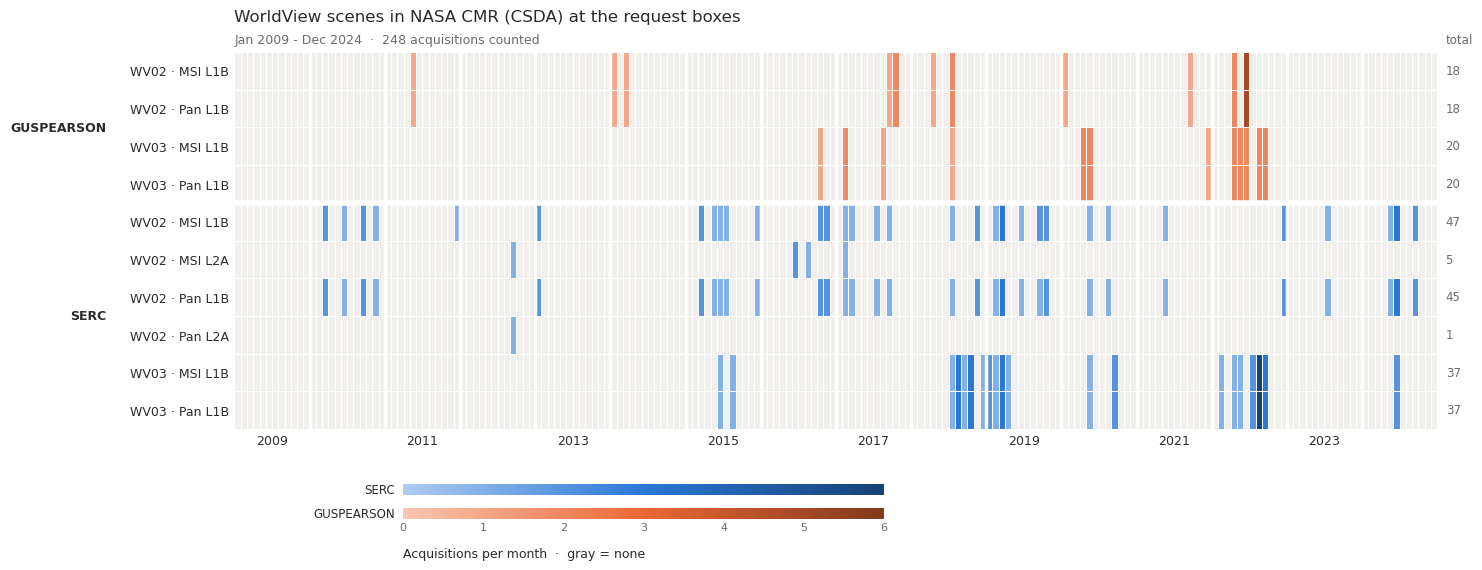

In [6]:
avail = sel.drop_duplicates(['site_name', 'vendor_item_id', 'band_set']).assign(product=lambda d: d.band_set + ' ' + d.level)
table = multistac.month_table(avail.drop_duplicates(['site_name', 'vendor_item_id', 'product'])
                                   .assign(id=lambda d: d.site_name + d.vendor_item_id + d['product']),
                              by=['site_name', 'sensor', 'product'])
fig, ax = mp.plot_month_heatmap(table, rows=['site_name', 'sensor', 'product'], color_by='site_name', log=False,
                                start='2009-01', end='2024-12', title='WorldView scenes in NASA CMR (CSDA) at the request boxes')
plt.show()

## 2. Top 5 scenes per site

In [7]:
def rank(site):
    t0, t1 = (pd.Timestamp(x) for x in TARGETS[site]['window'])
    s = scenes[scenes.site_name == site].copy()
    s['days_from_target'] = [0 if t0 <= d.normalize() <= t1 else min(abs((d - t0).days), abs((d - t1).days)) for d in s.date]
    s['why_out'] = ''
    s.loc[s.level.isna(), 'why_out'] += 'no MSI+Pan pair; '
    s.loc[s.off_nadir > OFF_NADIR_MAX, 'why_out'] += f'off-nadir > {OFF_NADIR_MAX}; '
    s.loc[s.cloud > CLOUD_MAX, 'why_out'] += f'cloud > {CLOUD_MAX}; '
    s.loc[s.aoi_cover < MIN_AOI_COVER, 'why_out'] += 'box not covered; '
    if TARGETS[site]['months']:
        s.loc[~s.month.isin(TARGETS[site]['months']), 'why_out'] += 'season; '
    s['nadir_ok'] = np.where(s.off_nadir <= 15, '<=15', '15-20')
    return s.sort_values(['days_from_target', 'off_nadir', 'cloud'])

COLS = ['site_name', 'date', 'sensor', 'catalog_id', 'level', 'off_nadir', 'cloud', 'aoi_cover',
        'msi_parts', 'pan_parts', 'days_from_target']
ranked = {site: rank(site) for site in TARGETS}
top = pd.concat([r[r.why_out == ''].head(TOP_N) for r in ranked.values()], ignore_index=True)
display(top[COLS])

# Closest scenes that were excluded, and why
for site, r in ranked.items():
    print(f'\n{site}: nearest excluded'); print(r[r.why_out != ''].head(3)[COLS[1:] + ['why_out']].to_string(index=False))

,site_name,date,sensor,catalog_id,level,off_nadir,cloud,aoi_cover,msi_parts,pan_parts,days_from_target
0,SERC,2017-09-28 16:05:58.485894,WV02,103001007258BA00,L1B,10.6,0.3,1.0,2.0,2.0,55
1,SERC,2016-10-19 15:59:16.747680,WV02,103001005E7BD000,L1B,19.3,5.4,1.0,1.0,1.0,284
2,SERC,2018-07-08 16:03:08.163989,WV02,10300100811F9600,L1B,15.1,6.7,1.0,1.0,1.0,338
3,SERC,2018-09-29 16:27:03.010323,WV03,1040010042958E00,L1B,11.4,7.1,1.0,1.0,1.0,421
4,SERC,2015-08-04 16:05:00.545103,WV03,104001000FB41300,L1B,4.8,0.0,1.0,2.0,2.0,726
5,GUSPEARSON,2014-01-02 18:43:40.083575,WV02,103001002BBE2F00,L1B,15.2,0.0,1.0,2.0,2.0,186
6,GUSPEARSON,2017-02-15 18:42:36.607575,WV03,1040010028B3ED00,L1B,19.6,0.0,1.0,1.0,1.0,1326
7,GUSPEARSON,2017-08-08 18:42:56.950575,WV03,10400100307CEB00,L1B,4.6,0.3,1.0,1.0,1.0,1500
8,GUSPEARSON,2017-10-02 18:40:23.096750,WV02,1030010072492D00,L1B,19.5,1.2,1.0,1.0,1.0,1555
9,GUSPEARSON,2017-10-13 18:35:30.844950,WV02,103001007064A600,L1B,13.1,0.0,1.0,1.0,1.0,1566



SERC: nearest excluded
                      date sensor       catalog_id level  off_nadir  cloud  aoi_cover  msi_parts  pan_parts  days_from_target                                   why_out
2017-07-14 16:03:56.153341   WV02 103001006C57E000   L1B       13.2   59.4      1.000        2.0        2.0                16                              cloud > 20; 
2017-03-06 16:04:40.618582   WV02 1030010065CE4500   L1B       27.7    0.0      0.318        2.0        2.0               146 off-nadir > 20; box not covered; season; 
2017-02-20 16:20:56.449817   WV02 1030010064234900  None       25.1    NaN        NaN        NaN        NaN               160 no MSI+Pan pair; off-nadir > 20; season; 

GUSPEARSON: nearest excluded
                      date sensor       catalog_id level  off_nadir  cloud  aoi_cover  msi_parts  pan_parts  days_from_target                           why_out
2014-03-03 18:33:27.100375   WV02 103001002D4C1700   L1B       27.1    6.2      0.712        2.0        2.0       

## 3. Download

Assets per granule: `ntf` (the NITF image) and `tar` (metadata only: IMD, RPB, TIL, ATT, EPH, GEO, XML,
README, browse JPG, GIS shapefiles). The `tar` holds no imagery.
Files go to `OUT_DIR/csda-cmr/<collection>/<granule>/`.

Protected files sit behind CSDA's own Cognito sign-in (not an Earthdata token). The sign-in cell asks for
your **Cognito** username, password and authenticator MFA code, the same flow as
`earthdata_s3_access_test.ipynb` (nothing is stored). With `DOWNLOAD_VIA = 's3'`, files come from the
S3 bucket (`csda-cumulus-prod-protected-5047`) using temporary AWS keys from
`https://data.csdap.earthdata.nasa.gov/s3credentials`, renewed automatically every hour. The CSDA bucket policy only
allows in-region access, so from this server S3 gives 403 Forbidden: set `DOWNLOAD_VIA = 'https'` here, and
`'s3'` on a cloud platform. If the keys expire mid-run, sign in again and rerun the download cell;
finished files are skipped.

In [8]:
granules = [gid for ids in top.granules for gid in ids]
plan = md.download(res, OUT_DIR, assets=ASSETS, ids=granules, dry_run=True)
print(len(plan), 'files for', top.shape[0], 'scenes'); plan[['collection', 'id', 'asset', 'filename', 's3_href']].head(10)

52 files for 10 scenes


,collection,id,asset,filename,s3_href
0,WV02_Pan_L1B,WV02_20140102184340_103001002BBE2F00_14JAN02184340-P1BS-505334568100_01_P007,ntf,WV02_20140102184340_103001002BBE2F00_14JAN02184340-P1BS-505334568100_01_P007.ntf,s3://csda-cumulus-prod-protected-5047/WV02_Pan_L1B___1/2014/002/WV02_20140102184340_10...
1,WV02_Pan_L1B,WV02_20140102184340_103001002BBE2F00_14JAN02184340-P1BS-505334568100_01_P007,tar,WV02_20140102184340_103001002BBE2F00_14JAN02184340-P1BS-505334568100_01_P007.tar,s3://csda-cumulus-prod-protected-5047/WV02_Pan_L1B___1/2014/002/WV02_20140102184340_10...
2,WV02_MSI_L1B,WV02_20140102184340_103001002BBE2F00_14JAN02184340-M1BS-505334568100_01_P007,ntf,WV02_20140102184340_103001002BBE2F00_14JAN02184340-M1BS-505334568100_01_P007.ntf,s3://csda-cumulus-prod-protected-5047/WV02_MSI_L1B___1/2014/002/WV02_20140102184340_10...
3,WV02_MSI_L1B,WV02_20140102184340_103001002BBE2F00_14JAN02184340-M1BS-505334568100_01_P007,tar,WV02_20140102184340_103001002BBE2F00_14JAN02184340-M1BS-505334568100_01_P007.tar,s3://csda-cumulus-prod-protected-5047/WV02_MSI_L1B___1/2014/002/WV02_20140102184340_10...
4,WV02_Pan_L1B,WV02_20140102184341_103001002BBE2F00_14JAN02184341-P1BS-505334568100_01_P008,ntf,WV02_20140102184341_103001002BBE2F00_14JAN02184341-P1BS-505334568100_01_P008.ntf,s3://csda-cumulus-prod-protected-5047/WV02_Pan_L1B___1/2014/002/WV02_20140102184341_10...
5,WV02_Pan_L1B,WV02_20140102184341_103001002BBE2F00_14JAN02184341-P1BS-505334568100_01_P008,tar,WV02_20140102184341_103001002BBE2F00_14JAN02184341-P1BS-505334568100_01_P008.tar,s3://csda-cumulus-prod-protected-5047/WV02_Pan_L1B___1/2014/002/WV02_20140102184341_10...
6,WV02_MSI_L1B,WV02_20140102184341_103001002BBE2F00_14JAN02184341-M1BS-505334568100_01_P008,ntf,WV02_20140102184341_103001002BBE2F00_14JAN02184341-M1BS-505334568100_01_P008.ntf,s3://csda-cumulus-prod-protected-5047/WV02_MSI_L1B___1/2014/002/WV02_20140102184341_10...
7,WV02_MSI_L1B,WV02_20140102184341_103001002BBE2F00_14JAN02184341-M1BS-505334568100_01_P008,tar,WV02_20140102184341_103001002BBE2F00_14JAN02184341-M1BS-505334568100_01_P008.tar,s3://csda-cumulus-prod-protected-5047/WV02_MSI_L1B___1/2014/002/WV02_20140102184341_10...
8,WV03_Pan_L1B,WV03_20170215184236_1040010028B3ED00_17FEB15184236-P1BS-504224959090_01_P002,ntf,WV03_20170215184236_1040010028B3ED00_17FEB15184236-P1BS-504224959090_01_P002.ntf,s3://csda-cumulus-prod-protected-5047/WV03_Pan_L1B___1/2017/046/WV03_20170215184236_10...
9,WV03_Pan_L1B,WV03_20170215184236_1040010028B3ED00_17FEB15184236-P1BS-504224959090_01_P002,tar,WV03_20170215184236_1040010028B3ED00_17FEB15184236-P1BS-504224959090_01_P002.tar,s3://csda-cumulus-prod-protected-5047/WV03_Pan_L1B___1/2017/046/WV03_20170215184236_10...


In [9]:
md.cumulus_login()   # asks for your Cognito username, password and MFA code

CSDA Cognito username:  montesano
CSDA Cognito password:  ········
CSDA authenticator MFA code:  027443


Signed in to the CSDA archive; temporary S3 credentials acquired


In [10]:
manifest = md.download(res, OUT_DIR, assets=ASSETS, ids=granules, via=DOWNLOAD_VIA)
print(manifest.status.value_counts().to_string())
manifest[manifest.status == 'failed'][['id', 'asset', 'error']]

downloads: 100%|██████████| 52/52 [00:56<00:00,  1.09s/it]

downloaded    26
exists        26


,id,asset,error


Unpack the metadata tars next to the images and check each granule has its NTF and IMD.

In [11]:
def unpack(tar_path):
    dest = tar_path.parent
    with tarfile.open(tar_path) as tf:
        members = [m for m in tf.getmembers() if m.isfile() and not Path(m.name).is_absolute() and '..' not in Path(m.name).parts]
        tf.extractall(dest, members=members)
    return dest

rows = []
for p in manifest[(manifest.asset == 'tar') & manifest.status.isin(['downloaded', 'exists'])].path:
    d = unpack(Path(p))
    files = [f for f in d.rglob('*') if f.is_file()]
    rows.append({'granule': d.name, 'ntf': sum(f.suffix.upper() == '.NTF' for f in files),
                 'imd': sum(f.suffix.upper() == '.IMD' for f in files), 'files': len(files)})
pd.DataFrame(rows)

,granule,ntf,imd,files
0,WV02_20140102184340_103001002BBE2F00_14JAN02184340-P1BS-505334568100_01_P007,1,1,35
1,WV02_20140102184340_103001002BBE2F00_14JAN02184340-M1BS-505334568100_01_P007,1,1,35
2,WV02_20140102184341_103001002BBE2F00_14JAN02184341-P1BS-505334568100_01_P008,1,1,35
3,WV02_20140102184341_103001002BBE2F00_14JAN02184341-M1BS-505334568100_01_P008,1,1,35
4,WV03_20170215184236_1040010028B3ED00_17FEB15184236-P1BS-504224959090_01_P002,1,1,33
5,WV03_20170215184236_1040010028B3ED00_17FEB15184236-M1BS-504224959090_01_P002,1,1,33
6,WV03_20170808184256_10400100307CEB00_17AUG08184256-P1BS-505620268100_01_P001,1,1,35
7,WV03_20170808184256_10400100307CEB00_17AUG08184256-M1BS-505620268100_01_P001,1,1,35
8,WV02_20171002184023_1030010072492D00_17OCT02184023-M1BS-505334680070_01_P003,1,1,35
9,WV02_20171002184023_1030010072492D00_17OCT02184023-P1BS-505334680070_01_P003,1,1,35


## 4. Quicklooks: NIR-red-green (MSI bands 7-5-3), clipped to the request box
L1B images are warped with their RPCs (no DEM) onto a ~2 m lat/lon grid; strip parts are mosaicked.

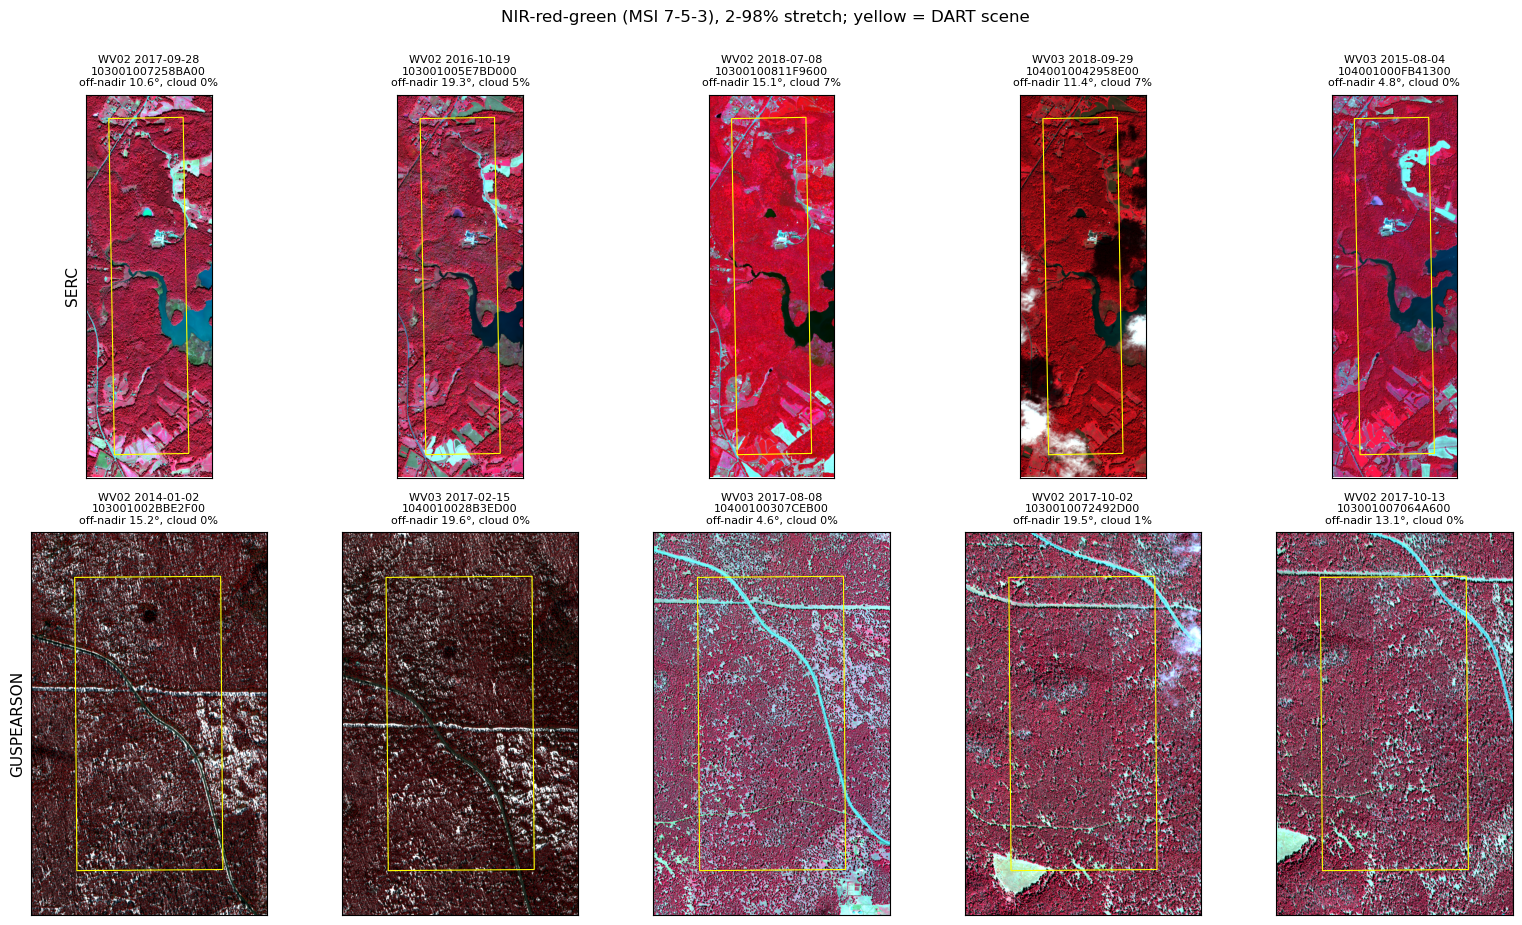

In [12]:
RES_DEG = 2e-5        # ~2 m
BANDS = [7, 5, 3]     # WV-2/WV-3 MSI: NIR1, red, green

def find_ntf(granule_id):
    d = OUT_DIR / 'csda-cmr'
    hits = [f for f in d.glob(f'*/{granule_id}/**/*') if f.suffix.upper() == '.NTF']
    return hits[0] if hits else None

def quicklook(scene):
    minx, miny, maxx, maxy = box_of[scene.site_name].bounds
    w, h = int(np.ceil((maxx - minx) / RES_DEG)), int(np.ceil((maxy - miny) / RES_DEG))
    transform = from_origin(minx, maxy, RES_DEG, RES_DEG)
    out = np.zeros((3, h, w), dtype='float32')
    for gid in [x for x in scene.granules if '-M1BS-' in x or '-M2AS-' in x]:
        ntf = find_ntf(gid)
        if ntf is None:
            continue
        with rasterio.open(ntf) as src:
            part = np.zeros_like(out)
            kw = dict(rpcs=src.rpcs) if src.rpcs and src.crs is None else dict(src_transform=src.transform, src_crs=src.crs)
            reproject(rasterio.band(src, BANDS), part, dst_transform=transform, dst_crs='EPSG:4326',
                      src_nodata=0, dst_nodata=0, resampling=Resampling.bilinear, **kw)
        out = np.where(out > 0, out, part)
    if not out.any():
        return None
    rgb = np.empty((h, w, 3), dtype='float32')
    for i in range(3):
        b = out[i]; v = b[b > 0]
        lo, hi = np.percentile(v, [2, 98]) if v.size else (0, 1)
        rgb[..., i] = np.clip((b - lo) / max(hi - lo, 1e-6), 0, 1)
    return rgb, (minx, maxx, miny, maxy)

site_list = list(TARGETS)
fig, axes = plt.subplots(len(site_list), TOP_N, figsize=(3.2 * TOP_N, 4.6 * len(site_list)), squeeze=False)
for r, site in enumerate(site_list):
    rows_ = top[top.site_name == site].reset_index(drop=True)
    for c in range(TOP_N):
        ax = axes[r, c]; ax.set_xticks([]); ax.set_yticks([])
        if c >= len(rows_):
            ax.axis('off'); continue
        s = rows_.iloc[c]
        ql = quicklook(s)
        if ql is None:
            ax.text(0.5, 0.5, 'no NTF found', ha='center', va='center', transform=ax.transAxes)
        else:
            ax.imshow(ql[0], extent=ql[1], aspect=1 / np.cos(np.radians(np.mean(ql[1][2:]))))
            scene_poly = aois[(aois.site == site) & (aois.kind == 'scene')]
            scene_poly.boundary.plot(ax=ax, color='yellow', lw=0.8)
        ax.set_title(f"{s.sensor} {s.date:%Y-%m-%d}\n{s.catalog_id}\noff-nadir {s.off_nadir:.1f}°, cloud {s.cloud:.0f}%", fontsize=8)
    axes[r, 0].set_ylabel(site, fontsize=11)
fig.suptitle('NIR-red-green (MSI 7-5-3), 2-98% stretch; yellow = DART scene', y=1.0)
fig.tight_layout(); plt.show()